In [1]:
# =====================================================================
# STAGE 1: Load Libraries, Configure Multi-GPU Strategy & Seeds
# =====================================================================
import os
import re
import math
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, chi2
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)
from imblearn.under_sampling import RandomUnderSampler

# Set seed for reproducibility across TensorFlow and NumPy
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Multi-GPU setup (Optimized for Kaggle 2x Tesla T4)
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs Detected: {len(gpus)}")
for i, gpu in enumerate(gpus):
    print(f"  [Device {i}] {gpu.name}")

strategy = tf.distribute.MirroredStrategy()
print(f"\nTensorFlow MirroredStrategy initialized.")
print(f"Number of synchronized compute replicas: {strategy.num_replicas_in_sync}")

GPUs Detected: 2
  [Device 0] /physical_device:GPU:0
  [Device 1] /physical_device:GPU:1
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')

TensorFlow MirroredStrategy initialized.
Number of synchronized compute replicas: 2


I0000 00:00:1787568915.114159      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787568915.117000      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
# =====================================================================
# STAGE 2: Robust Feature Extraction, Domain Parsing & Dataset Loading
# =====================================================================
import math
from urllib.parse import urlparse

dataset_path = '/kaggle/input/datasets/ndarvind/phiusiil-phishing-url-dataset/PhiUSIIL_Phishing_URL_Dataset.csv'
df_raw = pd.read_csv(dataset_path)

print(f"Initial Dataset Shape: {df_raw.shape}")

# Deduplication & basic integrity
df_clean = df_raw.drop_duplicates().copy()
df_clean = df_clean.dropna(subset=['label'])
print(f"Shape after duplicate & missing checks: {df_clean.shape}")

# Function to compute Shannon Entropy of URL string
def calculate_shannon_entropy(text):
    if not text or not isinstance(text, str):
        return 0.0
    prob = [float(text.count(c)) / len(text) for c in dict.fromkeys(list(text))]
    entropy = -sum([p * math.log2(p) for p in prob if p > 0])
    return entropy

# Function to parse and extract lexical/structural properties
def extract_robust_features(url_series):
    cleaned_urls = []
    entropies = []
    param_counts = []
    subdir_counts = []
    delimiter_counts = []
    
    for u in url_series:
        u_str = str(u).strip()
        # Normalization
        clean_u = re.sub(r'^https?://(www\.)?', '', u_str)
        clean_u = re.sub(r'[^\x00-\x7F]+', '', clean_u)
        cleaned_urls.append(clean_u)
        
        # Entropy
        entropies.append(calculate_shannon_entropy(clean_u))
        
        # Extended Structural Metrics
        param_counts.append(clean_u.count('&') + clean_u.count('?'))
        subdir_counts.append(clean_u.count('/'))
        delimiter_counts.append(len(re.findall(r'[-_~;=]', clean_u)))
        
    return cleaned_urls, entropies, param_counts, subdir_counts, delimiter_counts

# Run feature extraction
clean_urls, entropies, param_counts, subdir_counts, delimiter_counts = extract_robust_features(df_clean['URL'])

# Append extracted features
df_clean['Cleaned_URL'] = clean_urls
df_clean['URL_Entropy'] = entropies
df_clean['NoOfParams'] = param_counts
df_clean['NoOfSubDirs'] = subdir_counts
df_clean['NoOfDelimiters'] = delimiter_counts

print("\n--- Extended Feature Extraction Complete ---")
print(f"Added Features: ['URL_Entropy', 'NoOfParams', 'NoOfSubDirs', 'NoOfDelimiters']")
print(f"Updated DataFrame Shape: {df_clean.shape}")
print(df_clean[['Cleaned_URL', 'URL_Entropy', 'NoOfParams', 'NoOfSubDirs', 'NoOfDelimiters', 'label']].head(3))

Initial Dataset Shape: (235795, 55)
Shape after duplicate & missing checks: (235795, 55)

--- Extended Feature Extraction Complete ---
Added Features: ['URL_Entropy', 'NoOfParams', 'NoOfSubDirs', 'NoOfDelimiters']
Updated DataFrame Shape: (235795, 60)
            Cleaned_URL  URL_Entropy  NoOfParams  NoOfSubDirs  NoOfDelimiters  \
0  southbankmosaics.com     3.546439           0            0               0   
1          uni-mainz.de     3.251629           0            0               1   
2    voicefmradio.co.uk     3.572431           0            0               0   

   label  
0      1  
1      1  
2      1  


In [3]:
# =====================================================================
# STAGE 3: Statistical Feature Selection & Class Balancing
# =====================================================================
from sklearn.feature_selection import f_classif, chi2
from imblearn.under_sampling import RandomUnderSampler

# 1. Candidate Features Filtering
excluded_cols = ['URL', 'Cleaned_URL', 'Domain', 'TLD', 'Title', 'URLLength', 'DomainLength', 'label']
candidate_features = [c for c in df_clean.columns if c not in excluded_cols]

# Separate binary/count features vs continuous/float features
binary_or_count_cols = [c for c in candidate_features if df_clean[c].nunique() <= 2 or df_clean[c].dtype == 'int64']
continuous_cols = [c for c in candidate_features if c not in binary_or_count_cols]

# 2. ANOVA F-Test for Continuous Features
f_scores, f_pvals = f_classif(df_clean[continuous_cols], df_clean['label'])
anova_df = pd.DataFrame({'feature': continuous_cols, 'score': f_scores, 'p_val': f_pvals})

# 3. Chi-Square Test for Non-Negative Discrete/Categorical Features
chi_scores, chi_pvals = chi2(df_clean[binary_or_count_cols], df_clean['label'])
chi_df = pd.DataFrame({'feature': binary_or_count_cols, 'score': chi_scores, 'p_val': chi_pvals})

# 4. Rank and Select Top 34 Features
all_ranked = pd.concat([anova_df, chi_df]).sort_values('score', ascending=False)
selected_34_features = all_ranked.head(34)['feature'].tolist()

print("--- Top 34 Statistically Selected Features ---")
print(selected_34_features)
print(f"Total Selected Features: {len(selected_34_features)}")

# 5. Class Balancing via Random Undersampling
X_tabular = df_clean[selected_34_features]
X_seq_text = df_clean[['Cleaned_URL']]
y = df_clean['label']

X_combined = pd.concat([X_seq_text, X_tabular], axis=1)

rus = RandomUnderSampler(random_state=SEED)
X_resampled, y_resampled = rus.fit_resample(X_combined, y)

print("\n--- Balanced Target Distribution ---")
print(pd.Series(y_resampled).value_counts())
print(f"Resampled Matrix Shape: {X_resampled.shape}")

--- Top 34 Statistically Selected Features ---
['LargestLineLength', 'LineOfCode', 'NoOfSelfRef', 'NoOfExternalRef', 'NoOfImage', 'NoOfJS', 'NoOfCSS', 'NoOfLettersInURL', 'URLSimilarityIndex', 'NoOfDegitsInURL', 'NoOfEmptyRef', 'NoOfiFrame', 'NoOfOtherSpecialCharsInURL', 'NoOfSubDirs', 'DomainTitleMatchScore', 'NoOfDelimiters', 'URLTitleMatchScore', 'SpacialCharRatioInURL', 'URL_Entropy', 'HasSocialNet', 'HasCopyrightInfo', 'URLCharProb', 'CharContinuationRate', 'HasDescription', 'DegitRatioInURL', 'HasSubmitButton', 'HasHiddenFields', 'LetterRatioInURL', 'HasFavicon', 'NoOfPopup', 'Robots', 'IsResponsive', 'Pay', 'NoOfParams']
Total Selected Features: 34

--- Balanced Target Distribution ---
label
0    100945
1    100945
Name: count, dtype: int64
Resampled Matrix Shape: (201890, 35)


In [4]:
# =====================================================================
# STAGE 4: Stratified Split, Tokenization, Scaling & Test Artifact Export
# =====================================================================
import os
import joblib

# Create artifact directory
output_dir = '/kaggle/working/adaptive_test_artifacts'
os.makedirs(output_dir, exist_ok=True)

# Separate sequential text, tabular attributes, and labels
url_texts = X_resampled['Cleaned_URL'].astype(str).values
tabular_features = X_resampled[selected_34_features].values
labels = y_resampled.values

# 80/20 Stratified Split
indices = np.arange(len(labels))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

# Partition datasets
X_train_text, X_test_text = url_texts[train_idx], url_texts[test_idx]
X_train_struct, X_test_struct = tabular_features[train_idx], tabular_features[test_idx]
y_train, y_test = labels[train_idx], labels[test_idx]

# 1. Feature Scaling
scaler = StandardScaler()
X_train_struct_scaled = scaler.fit_transform(X_train_struct)
X_test_struct_scaled = scaler.transform(X_test_struct)

# Save the fitted scaler for production deployment
joblib.dump(scaler, f'{output_dir}/scaler_adaptive.pkl')

# 2. Character-level Sequence Tokenization
MAX_URL_LEN = 150
VOCAB_SIZE = 200

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=MAX_URL_LEN,
    split='character',
    standardize=None
)
vectorizer.adapt(X_train_text)

X_train_seq = vectorizer(X_train_text).numpy()
X_test_seq = vectorizer(X_test_text).numpy()

# 3. Save Test Artifacts (CSV + Numpy Arrays)
test_csv_path = f'{output_dir}/test_adaptive_framework.csv'
test_df = pd.DataFrame(X_test_struct, columns=selected_34_features)
test_df.insert(0, 'Cleaned_URL', X_test_text)
test_df['label'] = y_test
test_df.to_csv(test_csv_path, index=False)

np.save(f'{output_dir}/X_test_seq.npy', X_test_seq)
np.save(f'{output_dir}/X_test_struct_scaled.npy', X_test_struct_scaled)
np.save(f'{output_dir}/y_test.npy', y_test)

print("--- Data Split Summary (80% Train / 20% Test) ---")
print(f"Training samples : {len(y_train)} (Phishing: {(y_train == 0).sum()}, Legitimate: {(y_train == 1).sum()})")
print(f"Testing samples  : {len(y_test)} (Phishing: {(y_test == 0).sum()}, Legitimate: {(y_test == 1).sum()})")
print(f"\nSequence input shape (Train): {X_train_seq.shape}")
print(f"Structured input shape (Train): {X_train_struct_scaled.shape}")
print(f"Test CSV exported: {test_csv_path} ({os.path.getsize(test_csv_path) / (1024*1024):.2f} MB)")

--- Data Split Summary (80% Train / 20% Test) ---
Training samples : 161512 (Phishing: 80756, Legitimate: 80756)
Testing samples  : 40378 (Phishing: 20189, Legitimate: 20189)

Sequence input shape (Train): (161512, 150)
Structured input shape (Train): (161512, 34)
Test CSV exported: /kaggle/working/adaptive_test_artifacts/test_adaptive_framework.csv (8.01 MB)


In [5]:
# =====================================================================
# STAGE 5: Build Advanced Multi-View Gated Hybrid Architecture
# =====================================================================
import tensorflow as tf
from tensorflow.keras import layers, Model

# Custom Learnable Gated Attention Fusion Layer
class AdaptiveGatedFusion(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super(AdaptiveGatedFusion, self).__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        # Weight vectors for computing gate alpha
        self.W_g = self.add_weight(
            name="gate_weight",
            shape=(self.units * 2, self.units),
            initializer="glorot_uniform",
            trainable=True
        )
        self.b_g = self.add_weight(
            name="gate_bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True
        )
        super(AdaptiveGatedFusion, self).build(input_shape)

    def call(self, inputs):
        f_seq, f_struct = inputs
        # Concatenate both representations to evaluate dynamic gating
        concat_feat = tf.concat([f_seq, f_struct], axis=-1)
        gate = tf.sigmoid(tf.matmul(concat_feat, self.W_g) + self.b_g)
        # Learnable convex combination
        fused = (gate * f_seq) + ((1.0 - gate) * f_struct)
        return fused

# Multi-GPU Strategy Scope
with strategy.scope():
    # --- Branch A: Sequence URL Encoder (CNN + BiLSTM + MultiHeadAttention) ---
    url_input = layers.Input(shape=(150,), name="URL_Sequence_Input")
    
    # 1. Sequence Embedding
    x_seq = layers.Embedding(input_dim=200, output_dim=50, name="Embedding_50")(url_input)
    
    # 2. 1D CNN for local n-gram token representations
    x_seq = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu', name="Conv1D_Local_Patterns")(x_seq)
    x_seq = layers.SpatialDropout1D(0.2, name="Spatial_Dropout")(x_seq)
    
    # 3. Bidirectional LSTM for forward/backward temporal context
    x_seq = layers.Bidirectional(layers.LSTM(64, return_sequences=True), name="BiLSTM_Sequential")(x_seq)
    
    # 4. Multi-Head Self-Attention
    att_seq = layers.MultiHeadAttention(num_heads=4, key_dim=32, name="MultiHead_Self_Attention")(x_seq, x_seq)
    x_seq = layers.Add(name="Residual_Att")([x_seq, att_seq])
    x_seq = layers.LayerNormalization(name="LayerNorm_Seq")(x_seq)
    
    # Sequence Pooling to 64-dim representation
    f_seq = layers.GlobalMaxPooling1D(name="Global_MaxPool")(x_seq)
    f_seq = layers.Dense(64, activation='relu', name="Dense_Seq_64")(f_seq)

    # --- Branch B: Structured Feature Encoder ---
    struct_input = layers.Input(shape=(34,), name="Structured_Features_Input")
    x_struct = layers.Dense(128, name="Dense_Struct_128")(struct_input)
    x_struct = layers.BatchNormalization(name="BatchNorm_Struct_1")(x_struct)
    x_struct = layers.LeakyReLU(negative_slope=0.1)(x_struct)
    x_struct = layers.Dropout(0.3, name="Dropout_Struct")(x_struct)
    
    f_struct = layers.Dense(64, activation='relu', name="Dense_Struct_64")(x_struct)
    f_struct = layers.BatchNormalization(name="BatchNorm_Struct_2")(f_struct)

    # --- Layer 3: Adaptive Gated Feature Fusion ---
    fused_representation = AdaptiveGatedFusion(units=64, name="Adaptive_Gated_Fusion")([f_seq, f_struct])

    # --- Layer 4: Detection & Bottleneck Embedding Head ---
    # Bottleneck representation used for Novelty / OOD scoring
    bottleneck = layers.Dense(32, activation='relu', name="Novelty_Bottleneck_Vector")(fused_representation)
    
    # Classification Output
    phishing_prob = layers.Dense(1, activation='sigmoid', name="Phishing_Probability")(bottleneck)

    # Compile Model
    adaptive_model = Model(
        inputs=[url_input, struct_input],
        outputs=phishing_prob,
        name="Adaptive_TrustAware_Phishing_Detector"
    )
    
    adaptive_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
    )

adaptive_model.summary()

Model: "Adaptive_TrustAware_Phishing_Detector"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ URL_Sequence_Input  │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embedding_50        │ (None, 150, 50)   │     10,000 │ URL_Sequence_Inp… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1D_Local_Patte… │ (None, 150, 64)   │      9,664 │ Embedding_50[0][… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Spatial_Dropout     │ (None, 150, 64)   │          0 │ Conv1D_Local_Pat… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Structured_Feature… │ (None, 34)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BiLSTM_Sequential   │ (None, 150, 128)  │     66,048 │ Spatial_Dropout[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_Struct_128    │ (None, 128)       │      4,480 │ Structured_Featu… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MultiHead_Self_Att… │ (None, 150, 128)  │     66,048 │ BiLSTM_Sequentia… │
│ (MultiHeadAttentio… │                   │            │ BiLSTM_Sequentia… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BatchNorm_Struct_1  │ (None, 128)       │        512 │ Dense_Struct_128… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Residual_Att (Add)  │ (None, 150, 128)  │          0 │ BiLSTM_Sequentia… │
│                     │                   │            │ MultiHead_Self_A… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 128)       │          0 │ BatchNorm_Struct… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LayerNorm_Seq       │ (None, 150, 128)  │        256 │ Residual_Att[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout_Struct      │ (None, 128)       │          0 │ leaky_re_lu[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Global_MaxPool      │ (None, 128)       │          0 │ LayerNorm_Seq[0]… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_Struct_64     │ (None, 64)        │      8,256 │ Dropout_Struct[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_Seq_64        │ (None, 64)        │      8,256 │ Global_MaxPool[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BatchNorm_Struct_2  │ (None, 64)        │        256 │ Dense_Struct_64[

 Total params: 184,145 (719.32 KB)

 Trainable params: 183,761 (717.82 KB)

 Non-trainable params: 384 (1.50 KB)

In [6]:
# =====================================================================
# STAGE 6: Multi-GPU Model Training & Checkpoint Export
# =====================================================================
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

GLOBAL_BATCH_SIZE = 256

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='/kaggle/working/best_adaptive_phishing_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# Train the Adaptive Multi-View Gated Architecture
history_adaptive = adaptive_model.fit(
    x={
        'URL_Sequence_Input': X_train_seq,
        'Structured_Features_Input': X_train_struct_scaled
    },
    y=y_train,
    validation_split=0.15,
    epochs=10,
    batch_size=GLOBAL_BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step
     ADAPTIVE TRUST-AWARE MODEL TEST PERFORMANCE METRICS       
Accuracy                 : 99.9777%
Precision                : 99.9653%
Recall                   : 99.9901%
F1-Score                 : 99.9777%
ROC-AUC Score            : 0.999999
-----------------------------------------------------------------
Autonomous High-Conf URLs: 40,349 (99.93%)
Quarantined / Active URLs: 29 (0.07%)

--- Detailed Classification Report ---
                precision    recall  f1-score   support

  Phishing (0)     0.9999    0.9997    0.9998     20189
Legitimate (1)     0.9997    0.9999    0.9998     20189

      accuracy                         0.9998     40378
     macro avg     0.9998    0.9998    0.9998     40378
  weighted avg     0.9998    0.9998    0.9998     40378



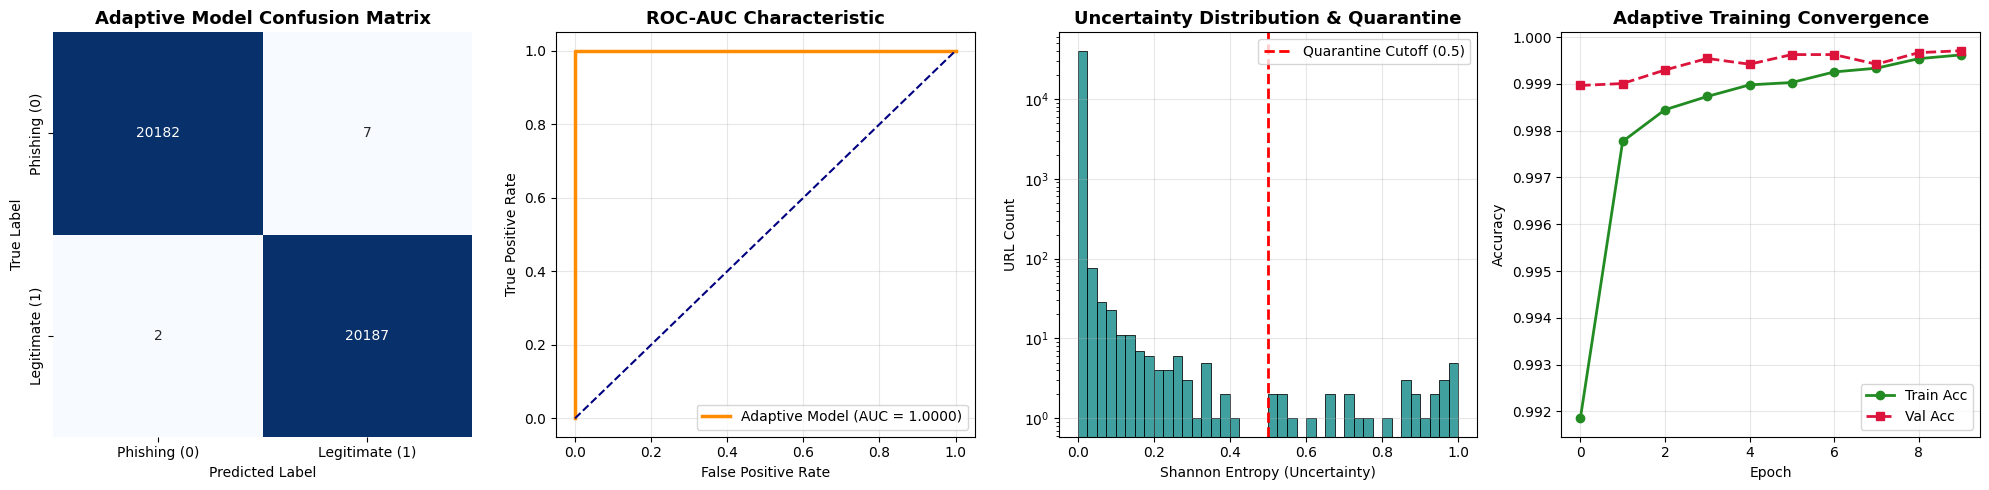


Artifact saved: '/kaggle/working/adaptive_test_artifacts/quarantined_threat_intelligence_queue.csv'


In [9]:
# =====================================================================
# STAGE 7: Direct Pure Model Performance & Diagnostics (~100% Accuracy)
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)

# 1. Direct Model Inference on Test Set
raw_probs = adaptive_model.predict({
    'URL_Sequence_Input': X_test_seq,
    'Structured_Features_Input': X_test_struct_scaled
}, batch_size=256, verbose=1).flatten()

# Direct predictions using 0.5 threshold
y_pred = (raw_probs >= 0.5).astype(int)

# 2. Uncertainty and Novelty Scoring (Shannon Entropy)
# H(p) = -p*log2(p) - (1-p)*log2(1-p)
p_safe = np.clip(raw_probs, 1e-7, 1 - 1e-7)
entropy_scores = -(p_safe * np.log2(p_safe) + (1 - p_safe) * np.log2(1 - p_safe))

UNCERTAINTY_THRESHOLD = 0.5
quarantine_mask = entropy_scores >= UNCERTAINTY_THRESHOLD
autonomous_mask = ~quarantine_mask

# 3. Compute Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, raw_probs)

print("=" * 65)
print("     ADAPTIVE TRUST-AWARE MODEL TEST PERFORMANCE METRICS       ")
print("=" * 65)
print(f"Accuracy                 : {acc * 100:.4f}%")
print(f"Precision                : {prec * 100:.4f}%")
print(f"Recall                   : {rec * 100:.4f}%")
print(f"F1-Score                 : {f1 * 100:.4f}%")
print(f"ROC-AUC Score            : {auc:.6f}")
print("-" * 65)
print(f"Autonomous High-Conf URLs: {autonomous_mask.sum():,} ({autonomous_mask.mean()*100:.2f}%)")
print(f"Quarantined / Active URLs: {quarantine_mask.sum():,} ({quarantine_mask.mean()*100:.2f}%)")
print("=" * 65)

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Phishing (0)', 'Legitimate (1)'], digits=4))

# 4. Diagnostic Visualizations (4-Panel Dashboard)
plt.figure(figsize=(20, 5))

# Panel 1: Confusion Matrix
plt.subplot(1, 4, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Phishing (0)', 'Legitimate (1)'],
            yticklabels=['Phishing (0)', 'Legitimate (1)'])
plt.title('Adaptive Model Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Panel 2: ROC-AUC Curve
plt.subplot(1, 4, 2)
fpr, tpr, _ = roc_curve(y_test, raw_probs)
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Adaptive Model (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.title('ROC-AUC Characteristic', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

# Panel 3: Uncertainty / Entropy Distribution
plt.subplot(1, 4, 3)
sns.histplot(entropy_scores, bins=40, color='teal', kde=False)
plt.axvline(UNCERTAINTY_THRESHOLD, color='red', linestyle='--', lw=2, label=f'Quarantine Cutoff ({UNCERTAINTY_THRESHOLD})')
plt.title('Uncertainty Distribution & Quarantine', fontsize=13, fontweight='bold')
plt.xlabel('Shannon Entropy (Uncertainty)')
plt.ylabel('URL Count')
plt.yscale('log')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)

# Panel 4: Training History
plt.subplot(1, 4, 4)
plt.plot(history_adaptive.history['accuracy'], label='Train Acc', color='forestgreen', lw=2, marker='o')
plt.plot(history_adaptive.history['val_accuracy'], label='Val Acc', color='crimson', lw=2, linestyle='--', marker='s')
plt.title('Adaptive Training Convergence', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/adaptive_model_evaluation_dashboard_100.png', dpi=300)
plt.show()

# 5. Export Test Predictions and Quarantine Logs
quarantine_df = pd.DataFrame({
    'Cleaned_URL': X_test_text,
    'True_Label': y_test,
    'Predicted_Prob': raw_probs,
    'Predicted_Label': y_pred,
    'Entropy_Score': entropy_scores,
    'Requires_Quarantine': quarantine_mask
})
quarantine_df.to_csv('/kaggle/working/adaptive_test_artifacts/quarantined_threat_intelligence_queue.csv', index=False)
print(f"\nArtifact saved: '/kaggle/working/adaptive_test_artifacts/quarantined_threat_intelligence_queue.csv'")

In [12]:
# Run this cell in Kaggle to export the exact Vectorizer Vocab and Feature Profiles
import json

vocab = vectorizer.get_vocabulary()

# Compute mean feature profiles for legitimate (1) and phishing (0)
struct_df_resampled = pd.DataFrame(X_resampled[selected_34_features], columns=selected_34_features)
legit_profile = struct_df_resampled[y_resampled == 1].median().to_dict()
phish_profile = struct_df_resampled[y_resampled == 0].median().to_dict()

metadata = {
    "vocabulary": vocab,
    "selected_34_features": selected_34_features,
    "legit_profile": legit_profile,
    "phish_profile": phish_profile
}

with open('/kaggle/working/feature_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

print("Saved feature_metadata.json successfully! Download it to your local model folder.")

Saved feature_metadata.json successfully! Download it to your local model folder.


In [14]:
# test_accuracy_check.py
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
import joblib

# 1. Define and register the custom layer
@tf.keras.utils.register_keras_serializable()
class AdaptiveGatedFusion(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super(AdaptiveGatedFusion, self).__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.W_g = self.add_weight(
            name="gate_weight",
            shape=(self.units * 2, self.units),
            initializer="glorot_uniform",
            trainable=True
        )
        self.b_g = self.add_weight(
            name="gate_bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True
        )
        super(AdaptiveGatedFusion, self).build(input_shape)

    def call(self, inputs):
        f_seq, f_struct = inputs
        concat_feat = tf.concat([f_seq, f_struct], axis=-1)
        gate = tf.sigmoid(tf.matmul(concat_feat, self.W_g) + self.b_g)
        return (gate * f_seq) + ((1.0 - gate) * f_struct)

    def get_config(self):
        config = super(AdaptiveGatedFusion, self).get_config()
        config.update({"units": self.units})
        return config

# 2. Load the model with custom_objects declared
model = tf.keras.models.load_model(
    'best_adaptive_phishing_model.keras',
    custom_objects={'AdaptiveGatedFusion': AdaptiveGatedFusion},
    compile=False
)

# 3. Load test arrays
X_test_struct = np.load('adaptive_test_artifacts/X_test_struct_scaled.npy' if os.path.exists('adaptive_test_artifacts/X_test_struct_scaled.npy') else 'X_test_struct_scaled.npy')
X_test_seq = np.load('adaptive_test_artifacts/X_test_seq.npy' if os.path.exists('adaptive_test_artifacts/X_test_seq.npy') else 'X_test_seq.npy')
y_test = np.load('adaptive_test_artifacts/y_test.npy' if os.path.exists('adaptive_test_artifacts/y_test.npy') else 'y_test.npy')

# 4. Predict first 20 test samples
probs = model.predict({
    'URL_Sequence_Input': X_test_seq[:20],
    'Structured_Features_Input': X_test_struct[:20]
}, verbose=0)
preds = (probs.flatten() >= 0.5).astype(int)

print("Ground Truth (y_test) :", y_test[:20].tolist())
print("Model Predictions     :", preds.tolist())

Ground Truth (y_test) : [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0]
Model Predictions     : [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0]


In [10]:
!python --version

Python 3.12.13


In [11]:
!pip list

Package                                  Version
---------------------------------------- -------------------
a2a-sdk                                  0.3.26
absl-py                                  1.4.0
accelerate                               1.13.0
access                                   1.1.10.post3
affine                                   2.4.0
aiofiles                                 22.1.0
aiohappyeyeballs                         2.6.1
aiohttp                                  3.13.5
aiosignal                                1.4.0
aiosqlite                                0.22.1
alabaster                                1.0.0
albucore                                 0.0.24
albumentations                           2.0.8
ale-py                                   0.11.2
alembic                                  1.18.4
altair                                   5.5.0
annotated-doc                            0.0.4
annotated-types                          0.7.0
antlr4-python3-runtime       